# 05_mendeley_data: Mendeley Data (Elsevier data repository)

Searched with the public API (data.mendeley.com/api/research-data/search, 76 Toxoplasma records); files downloaded through public-api links. MDPI journals were also checked and had no usable participant-level data.

**Same protocol for every dataset** (`datasets/common/protocol.py`): label = Toxoplasma IgG positive; every column that measures Toxoplasma itself (IgM, avidity, titre, OD, PCR, other kits) and identifiers are removed; logistic regression, random forest and XGBoost; ROC-AUC from 5-fold x 3 repeated stratified cross-validation with preprocessing inside the folds. Datasets with fewer than 20 positives or 20 negatives are catalogued but not evaluated.

**Sections:** setup → helpers → one section per dataset (where it comes from, how the label is coded, what is removed) → build and evaluate → chart. Outputs are written to `raw/`, `processed/`, `results.csv`, `DATASETS.md`.

In [1]:
# Setup: run from the repository root and load the shared protocol (datasets/common/*.ipynb)
import os, sys, warnings
os.environ['PYTHONWARNINGS'] = 'ignore'; warnings.filterwarnings('ignore')
while not os.path.isdir('datasets') and os.path.dirname(os.getcwd()) != os.getcwd():
    os.chdir('..')
sys.path.insert(0, 'scripts')          # curated loaders: scripts/external_datasets.py, us_datasets.py, europe_datasets.py
%run -i datasets/common/protocol.ipynb
%run -i datasets/common/folder_tools.ipynb
import pandas as pd
pd.set_option('display.max_colwidth', 60); pd.set_option('display.width', 200)
HERE = 'datasets/05_mendeley_data'
print('working directory:', os.getcwd())

working directory: /home/claude/toxo


**Notes on this source.** Mendeley Data (data.mendeley.com, Elsevier's data repository). Searched with its public API (76 Toxoplasma records,
mostly laboratory / animal); the human, individual-level ones are below. Files come from the public-api download links.

MDPI journals were also checked (21 papers with tables) but none had usable participant-level data: the Greek HIV table holds
only laboratory results, the Alzheimer table gives Toxoplasma only as raw antigen readings without a cut-off, and the
others are animal, laboratory or study-level (meta-analysis) tables.

## Helpers (curated loaders and source-specific functions)

In [2]:
L = 'repo_supp/mendeley_data/'

## Datasets

Each cell adds one dataset to `CONFIG`: `source` = where the raw file comes from, `label` / `pos` / `neg` = how the Toxoplasma IgG result is coded, `drop` = extra columns removed (leakage, identifiers, outcomes), `loader` = a hand-written loader in `scripts/` for datasets curated earlier.

In [3]:
CONFIG = []

### nigeria_pregnant

**Toxoplasmosis among pregnant women in Nigeria (Dr Onyinye study)**  
Nigeria · Pregnant women at antenatal clinics · DOI/ID: `10.17632/s84shxhhfv.1`

Rich direct exposures: cat possession / contact / litter / proximity, stray cats, gardening, farm work, undercooked and raw meat, untreated water, unpasteurised milk, water sources, HIV status. Baby outcomes removed.

In [4]:
CONFIG.append(dict(key='nigeria_pregnant', title='Toxoplasmosis among pregnant women in Nigeria (Dr Onyinye study)',
     doi='10.17632/s84shxhhfv.1', setting='Pregnant women at antenatal clinics', country='Nigeria',
     source=('local', L + 's84shxhhfv/Dr. Onyinye Toxoplasmosis Study among pregnant women in nigeria 2.xlsx'),
     file='Dr. Onyinye Toxoplasmosis Study among pregnant women in nigeria 2.xlsx', label='Result', pos=['yes'], neg=['no'],
     drop=['S/N', 'LabIgG', 'babyEYEinfection', 'hydocephalus', 'OtherTRIBE'],
     note='Rich direct exposures: cat possession / contact / litter / proximity, stray cats, gardening, farm work, '
          'undercooked and raw meat, untreated water, unpasteurised milk, water sources, HIV status. Baby outcomes removed.'))

### mexico_testosterone

**Toxoplasma infection, testosterone and psychopathological symptoms**  
Mexico · Adults, serologically tested · DOI/ID: `10.17632/dxg3498c7y.1`

Inputs: age, weight, height, BMI, sex, testosterone and SCL-90 symptom scales (possible consequences).

In [5]:
CONFIG.append(dict(key='mexico_testosterone', title='Toxoplasma infection, testosterone and psychopathological symptoms',
     doi='10.17632/dxg3498c7y.1', setting='Adults, serologically tested', country='Mexico',
     source=('local', L + 'dxg3498c7y/Data_Toxo_.xlsx'), file='Data_Toxo_.xlsx',
     label='IgG binary (1 = infected, 0 = non-infected)', pos=['1'], neg=['0'], drop=['IgG'],
     note='Inputs: age, weight, height, BMI, sex, testosterone and SCL-90 symptom scales (possible consequences).'))

### thailand_bangphae_children

**T. gondii seroprevalence by Sabin-Feldman dye test in children and young adults, Bangphae**  
Thailand · Healthy children and young adults, paired sera 2012 and 2015 · DOI/ID: `10.17632/mcw665mzrp.1`

Label = 2015 dye test; the 2012 result is removed (it measures the same infection).

In [6]:
CONFIG.append(dict(key='thailand_bangphae_children', title='T. gondii seroprevalence by Sabin-Feldman dye test in children and young adults, Bangphae',
     doi='10.17632/mcw665mzrp.1', setting='Healthy children and young adults, paired sera 2012 and 2015', country='Thailand',
     source=('local', L + 'mcw665mzrp/Seroprevalence of Toxoplasma gondii detected using dye test in children and young adults in Bangphae district,  Thailand.xlsx'),
     file='Seroprevalence of Toxoplasma gondii detected using dye test in children and young adults in Bangphae district,  Thailand.xlsx',
     label='seropositivity in Y2015', pos=['positive'], neg=['negative'], drop=['Subject ID', 'seropositivity in Y2012'],
     note='Label = 2015 dye test; the 2012 result is removed (it measures the same infection).'))

### japan_uveitis_patients

**Low Toxoplasma IgG seroprevalence in younger patients: ocular toxoplasmosis diagnosis**  
Japan · Ophthalmology patients tested for Toxoplasma IgG · DOI/ID: `10.17632/m4hvf5g7mj.1`

17 positives: below the 20-case minimum, catalogued only.

In [7]:
CONFIG.append(dict(key='japan_uveitis_patients', title='Low Toxoplasma IgG seroprevalence in younger patients: ocular toxoplasmosis diagnosis',
     doi='10.17632/m4hvf5g7mj.1', setting='Ophthalmology patients tested for Toxoplasma IgG', country='Japan',
     source=('local', L + 'm4hvf5g7mj/Data for repository.xlsx'), file='Data for repository.xlsx',
     label='positive:1, negative:０', pos=['1'], neg=['0'], drop=['patient No.', 'date of exam', 'final diagnosis', 'titier'],
     note='17 positives: below the 20-case minimum, catalogued only.'))

## Build and evaluate

Downloads (or copies) each raw file into `raw/`, builds `processed/<dataset>.csv`, removes leakage columns, then runs logistic regression, random forest and XGBoost with 5-fold x 3 cross-validation.

In [8]:
res = run(HERE, CONFIG)

nigeria_pregnant                   n=   250 pos=  171 feats= 43 best AUC=0.558 (RandomForest)


mexico_testosterone                n=   213 pos=   35 feats= 15 best AUC=0.67 (XGBoost)


thailand_bangphae_children         n=   573 pos=   24 feats=  5 best AUC=0.615 (LogReg)
japan_uveitis_patients             n=    83 pos=   17 feats=  4 best AUC=nan (not evaluated (fewer than 20 positives or negatives))


In [9]:
cols = ['dataset', 'country', 'n', 'positives', 'prevalence', 'n_features', 'LogReg_auc', 'RandomForest_auc', 'XGBoost_auc',
        'best_auc', 'best_model']
res[[c for c in cols if c in res]]

,dataset,country,n,positives,prevalence,n_features,LogReg_auc,RandomForest_auc,XGBoost_auc,best_auc,best_model
0,nigeria_pregnant,Nigeria,250,171,0.684,43,0.552,0.558,0.533,0.558,RandomForest
1,mexico_testosterone,Mexico,213,35,0.164,15,0.647,0.652,0.670,0.670,XGBoost
2,thailand_bangphae_children,Thailand,573,24,0.042,5,0.615,0.580,0.585,0.615,LogReg
3,japan_uveitis_patients,Japan,83,17,0.205,4,NaN,NaN,NaN,NaN,not evaluated (fewer than 20 positives or negatives)


## Chart

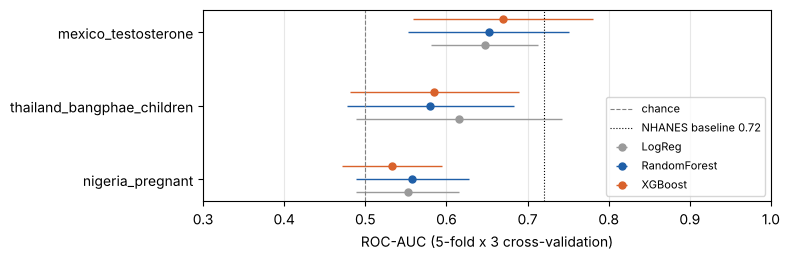

In [10]:
# ROC-AUC per dataset and model (error bars: SD over the 15 CV folds)
import matplotlib.pyplot as plt
r = res[res.best_auc.notna()].sort_values('best_auc')
if len(r):
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(r) + 1.2))
    for k, (m, c) in enumerate([('LogReg', '#9a9a9a'), ('RandomForest', '#1f5fa8'), ('XGBoost', '#d9622b')]):
        ax.errorbar(r[f'{m}_auc'], [i + (k - 1) * 0.18 for i in range(len(r))], xerr=r[f'{m}_sd'], fmt='o', ms=5,
                    color=c, label=m, elinewidth=1)
    ax.axvline(0.5, ls='--', color='grey', lw=0.8, label='chance')
    ax.axvline(0.72, ls=':', color='black', lw=0.8, label='NHANES baseline 0.72')
    ax.set_yticks(range(len(r))); ax.set_yticklabels(r.dataset)
    ax.set_xlabel('ROC-AUC (5-fold x 3 cross-validation)'); ax.set_xlim(0.3, 1.0)
    ax.legend(loc='lower right', fontsize=8); ax.grid(axis='x', alpha=0.3)
    plt.tight_layout(); plt.show()

## What was removed as leakage, and the inputs used

In [11]:
res[['dataset', 'removed_as_leakage', 'features']]

,dataset,removed_as_leakage,features
0,nigeria_pregnant,"AwarenessToxo, LabIgM, Results, LabIgGavidity, Resultss,...","maritalstatus, age, Occupation, education, tribe, reside..."
1,mexico_testosterone,,"Age, Weight, Height, BMI, Sex (0 = male, 1 = female), Te..."
2,thailand_bangphae_children,"Dye test titer in Y2012, Dye test titer in Y2015","Age(Y), Sex, Living area, Nutritional status in Y2012, N..."
3,japan_uveitis_patients,,"sex, age at exam, finding, laterarity"
